In [1]:
import sys
sys.path.append("..")

from datetime import datetime
import numpy as np
import ujson as json
import os
from tqdm import tqdm
import matplotlib.pyplot as plt
from lib.utils import get_samples_from_folder, load_transform
from copy import deepcopy
import pandas as pd
from lib.features import WPTFeatureExtractor
from typing import Tuple
import pickle 
from sklearn.pipeline import Pipeline
# from yaml import load, Loader

ModuleNotFoundError: No module named 'ujson'

In [2]:
import sys
from models.metric_learning import (
    DataLoader,
    FeatureReducer,
    get_proba_per_sample,
    create_triplets_idx,
    TripletDataset,
    FeatureReducerScikit
)

In [3]:
from sklearn.decomposition import PCA

In [4]:
plt.style.use("default")

In [5]:
PATH_TO_VALID_DATASET = "/workspaces/project/raw/sequence_1/"
PATH_TO_TRAIN_DATASET = "/workspaces/project/raw/sequence_2/"
PATH_MODELS = "../models/metric_learning/models_repo"

In [6]:
POSSIBLE_CABLES = [1,2,3,4]

# PCA

In [7]:
transformer = WPTFeatureExtractor(family="db16", level=4, normalize=True, threshold=0.95)
features_per_cable_train = load_transform(PATH_TO_TRAIN_DATASET, transformer)

100%|██████████| 4404/4404 [03:04<00:00, 23.89it/s]


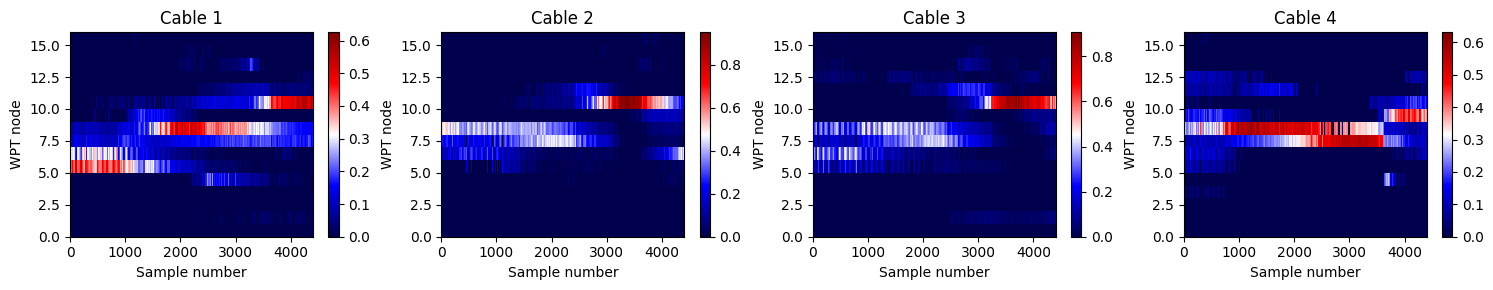

In [8]:
plt.figure(figsize=(15,3))
i = 1
for cable, features in features_per_cable_train.items():
    plt.subplot(1,4,i)
    cols = [c for c in features.columns if isinstance(c, int)]
    x = features[cols].to_numpy()
    plt.pcolormesh(x.T, cmap="seismic")
    plt.ylabel("WPT node")
    plt.xlabel("Sample number")
    plt.title(f"Cable {i}")
    plt.colorbar()
    i+=1
plt.tight_layout()

In [9]:
features_per_cable_valid = load_transform(PATH_TO_VALID_DATASET, transformer)

  0%|          | 0/2730 [00:00<?, ?it/s]

100%|██████████| 2730/2730 [01:46<00:00, 25.75it/s]


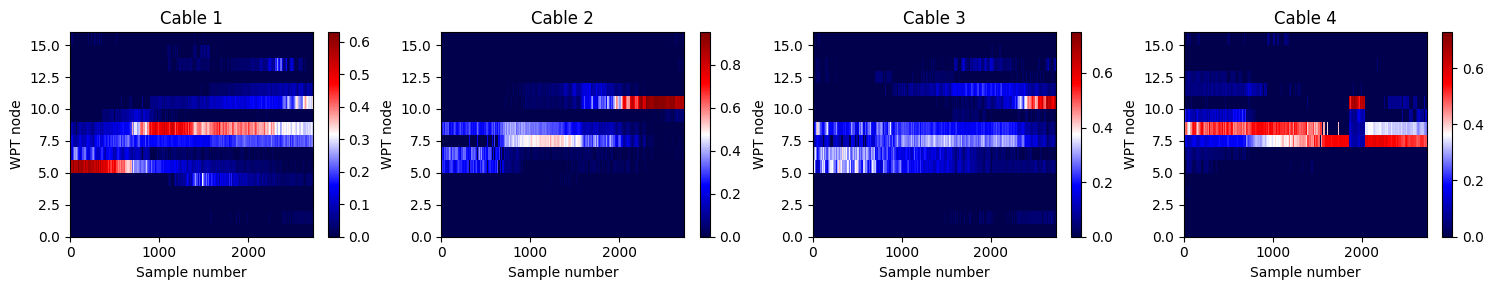

In [10]:
plt.figure(figsize=(15,3))
i = 1
for cable, features in features_per_cable_valid.items():
    plt.subplot(1,4,i)
    cols = [c for c in features.columns if isinstance(c, int)]
    x = features[cols].to_numpy()
    plt.pcolormesh(x.T, cmap="seismic")
    plt.ylabel("WPT node")
    plt.xlabel("Sample number")
    plt.title(f"Cable {i}")
    plt.colorbar()
    i+=1
plt.tight_layout()

In [11]:
pca_per_cable = {f"c{cable}": PCA(16) for cable in POSSIBLE_CABLES}

for cable, model in pca_per_cable.items():
    data = features_per_cable_train[cable]
    cols = [c for c in features_per_cable_train[cable].columns if isinstance(c, int)]
    data_numpy = data[cols].to_numpy()
    model.fit(data_numpy)

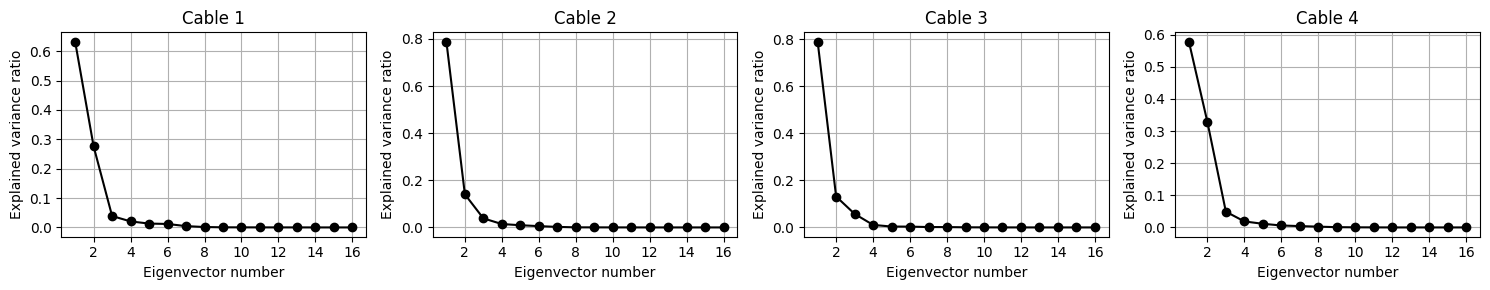

In [12]:
plt.figure(figsize=(15,3))
i = 1
for cable, model in pca_per_cable.items():
    plt.subplot(1,4,i)
    v = model.explained_variance_ratio_
    plt.plot(np.arange(1,len(v)+1), v, color="k", marker="o")
    plt.xticks(np.arange(2,len(v)+1,2))
    plt.ylabel("Explained variance ratio")
    plt.xlabel("Eigenvector number")
    plt.title(f"Cable {i}")
    i+=1
    plt.grid()
plt.tight_layout()

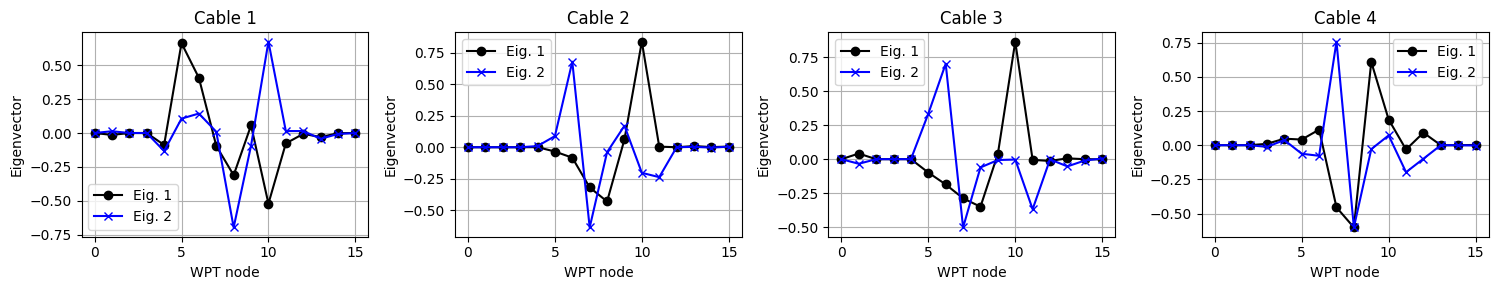

In [13]:
plt.figure(figsize=(15,3))
i = 1
for cable, model in pca_per_cable.items():
    plt.subplot(1,4,i)
    plt.plot(model.components_[0], color="k", marker="o")
    plt.plot(model.components_[1], color="blue", marker="x")
    plt.ylabel("Eigenvector")
    plt.xlabel("WPT node")
    plt.title(f"Cable {i}")
    plt.legend(["Eig. 1", "Eig. 2"])
    i+=1
    plt.grid()
plt.tight_layout()

In [14]:
reduced_per_cable_train = {}
reduced_per_cable_valid = {}
for cable, model in pca_per_cable.items():
    cols = [c for c in features_per_cable_train[cable].columns if isinstance(c, int)]
    data_train_numpy = features_per_cable_train[cable][cols].to_numpy()
    data_valid_numpy = features_per_cable_valid[cable][cols].to_numpy()

    reduced_per_cable_train[cable] = model.transform(data_train_numpy)
    reduced_per_cable_valid[cable] = model.transform(data_valid_numpy)

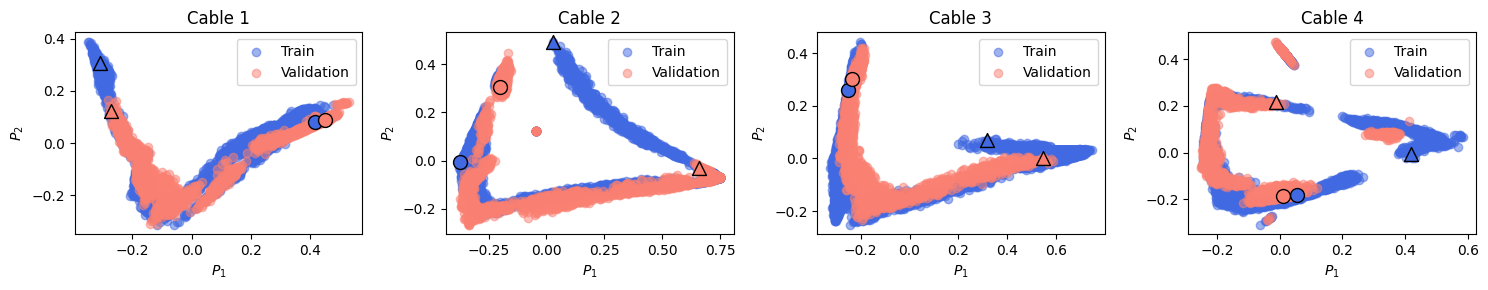

In [15]:
plt.figure(figsize=(15,3))

for i, cable in enumerate(reduced_per_cable_train):
    plt.subplot(1,4,i+1)
    plt.title(f"Cable {i+1}")
    plt.scatter(reduced_per_cable_train[cable][:,0], reduced_per_cable_train[cable][:,1], c="royalblue", alpha=0.5)
    plt.scatter(reduced_per_cable_valid[cable][:,0], reduced_per_cable_valid[cable][:,1], c="salmon", alpha=0.5)
    plt.legend(["Train", "Validation"])
    plt.scatter(reduced_per_cable_train[cable][0,0], reduced_per_cable_train[cable][0,1], c="royalblue", marker="o", s=100, edgecolor="k")
    plt.scatter(reduced_per_cable_train[cable][-1,0], reduced_per_cable_train[cable][-1,1], c="royalblue", marker="^", s=100, edgecolor="k")

    plt.scatter(reduced_per_cable_valid[cable][0,0], reduced_per_cable_valid[cable][0,1], c="salmon", marker="o", s=100, edgecolor="k")
    plt.scatter(reduced_per_cable_valid[cable][-1,0], reduced_per_cable_valid[cable][-1,1], c="salmon", marker="^", s=100, edgecolor="k")
    plt.xlabel("$P_1$")
    plt.ylabel("$P_2$")
plt.tight_layout()


In [35]:
from sklearn.neighbors import NearestNeighbors

In [51]:
def compute_dist(x, y):
    nn = NearestNeighbors()
    nn.fit(x)
    d = nn.kneighbors(y)[0].max(axis=1)
    return d.mean()

In [52]:
for cable in reduced_per_cable_train:
    d = compute_dist(reduced_per_cable_train[cable], reduced_per_cable_valid[cable])
    print(d)

0.0486727629697783
0.05032446226704456
0.08018526372634552
0.06205641838802407


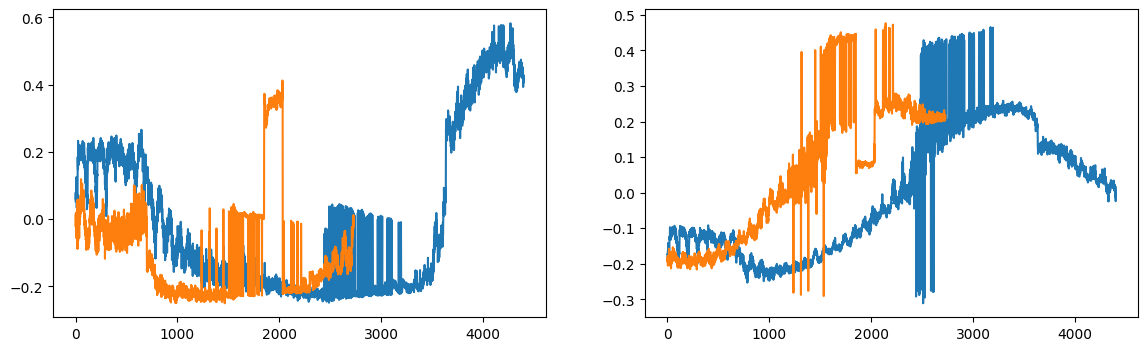

In [53]:
plt.figure(figsize=(14,4))
plt.subplot(1,2,1)
plt.plot(reduced_per_cable_train["c4"][:,0])
plt.plot(reduced_per_cable_valid["c4"][:,0])
plt.subplot(1,2,2)
plt.plot(reduced_per_cable_train["c4"][:,1])
plt.plot(reduced_per_cable_valid["c4"][:,1])